# EDA — Deserción en educación superior (Colombia), IES × año

Análisis exploratorio del dataset que produce `pipeline.py` (`data/processed/dataset_ies.csv`).
Cada fila es una IES en un año (2015–2021); la variable objetivo es `tasa_desercion` (SPADIES, MEN) y las
explicativas llegan rezagadas (Saber 11 y TerriData en t-1; matrícula SNIES en t-2). El contexto territorial se
une por el municipio sede de la IES.

**Alcance.** Se describen asociaciones, no causas, y el nivel de análisis es la institución, no el estudiante.

In [1]:
# Configuración: rutas relativas a la raíz del proyecto y librerías
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.collections import PatchCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Polygon
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.config import load_config
from src.homologation.divipola import cargar_divipola
from src.validate.dictionary import describir_columnas

# Paleta del proyecto: azul = oficial, naranja = privada; rampa azul para magnitudes
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8984"
RAMPA = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#1c5cab", "#0d366b"]
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

## 1. Carga y descripción general

In [2]:
cfg = load_config(ROOT / "config" / "config.yaml")
assert cfg["unidad_analisis"] == "ies", "este EDA es para la unidad IES x año"
ruta = ROOT / cfg["rutas"]["processed"] / "dataset_ies.csv"

# Los códigos son texto para conservar los ceros a la izquierda (p. ej. 05001)
df = pd.read_csv(ruta, dtype={"cod_ies": str, "cod_divipola_mpio": str, "sector": str, "caracter": str})
divipola = cargar_divipola(ROOT / cfg["rutas"]["raw"] / "dane" / "divipola.csv")
deptos = divipola.drop_duplicates("cod_depto").set_index("cod_depto")["depto_norm"].str.title()

df["cod_depto"] = df["cod_divipola_mpio"].str[:2]
df["departamento"] = df["cod_depto"].map(deptos)
df["naturaleza"] = df["sector"].map({"1": "Oficial", "2": "Privada"})  # id_sector de SNIES
assert df["tasa_desercion"].notna().all(), "tasa_desercion tiene nulos: falta el export de SPADIES"

print(f"{len(df):,} filas · {df['cod_ies'].nunique()} IES · años {df['anio'].min()}–{df['anio'].max()} · {df.shape[1]} columnas")
print("IES por naturaleza:", df.drop_duplicates("cod_ies")["naturaleza"].value_counts().to_dict())

1,928 filas · 295 IES · años 2015–2021 · 50 columnas
IES por naturaleza: {'Privada': 216, 'Oficial': 79}


In [3]:
# Control de la codificación de naturaleza contra el catálogo oficial de IES (sector Oficial/Privado)
catalogo = ROOT / cfg["rutas"]["raw"] / "snies" / "ies_catalogo.csv"
if catalogo.exists():
    cat = pd.read_csv(catalogo, dtype=str).rename(columns={"c_digo_instituci_n": "cod_ies", "sector": "sector_catalogo"})
    cruce = df.drop_duplicates("cod_ies").merge(cat[["cod_ies", "sector_catalogo"]], on="cod_ies", how="left")
    display(pd.crosstab(cruce["naturaleza"], cruce["sector_catalogo"].fillna("sin catálogo")))

sector_catalogo,Oficial,Privado
naturaleza,,
Oficial,79,0
Privada,1,215


In [4]:
# Tipos de dato y resumen de las variables numéricas
display(df.dtypes.to_frame("tipo").T)
display(df.describe().T.round(3))

,cod_ies,anio,tasa_desercion,posible_cierre,ratio_spadies_snies,inconsistencia_fuentes,regimen_especial,es_sena,log_matriculados_spadies_t2,cod_divipola_mpio,sector,caracter,matriculados_ies_t2,punt_global_media_t1,punt_global_mediana_t1,pct_estrato_bajo_t1,pct_colegio_oficial_t1,n_estudiantes_t1,mpio_matriculados_t2,mpio_ies_con_oferta_t2,...,td_ipm_censo_t1,td_mdm_t1,td_mdm_educacion_t1,td_mdm_gestion_t1,td_mdm_resultados_t1,td_miseria_pct_t1,td_nbi_pct_t1,td_pct_pob_15_19_t1,td_pct_pob_20_24_t1,td_pct_poblacion_rural_t1,td_repitencia_oficial_t1,td_transito_superior_t1,td_poblacion_total_t1,log_matriculados_ies_t2,falta_saber11,falta_mdm,falta_snies,cod_depto,departamento,naturaleza
tipo,str,int64,float64,bool,float64,bool,bool,bool,float64,str,str,str,float64,float64,float64,float64,float64,float64,int64,int64,...,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,bool,bool,bool,str,str,str


,count,mean,std,min,25%,50%,75%,max
anio,1928.0,2017.980,2.000,2015.000,2016.000,2018.000,2020.000,2021.000
tasa_desercion,1928.0,0.120,0.087,0.003,0.073,0.099,0.141,0.994
ratio_spadies_snies,1369.0,0.897,0.214,0.354,0.790,0.882,0.970,2.628
log_matriculados_spadies_t2,1928.0,7.897,1.411,4.635,6.896,8.077,8.946,12.867
matriculados_ies_t2,1369.0,8608.584,28355.260,39.000,1182.000,3789.000,9568.000,467643.000
punt_global_media_t1,1383.0,262.623,12.892,206.894,254.392,263.916,270.213,294.815
punt_global_mediana_t1,1383.0,260.064,14.253,201.000,250.000,263.000,267.000,295.000
pct_estrato_bajo_t1,1383.0,0.634,0.131,0.244,0.552,0.579,0.730,0.987
pct_colegio_oficial_t1,1383.0,0.626,0.120,0.347,0.529,0.620,0.699,1.000
n_estudiantes_t1,1383.0,36254.486,38194.511,214.000,4428.000,17316.000,88117.000,96708.000


## 2. Distribución de la tasa de deserción

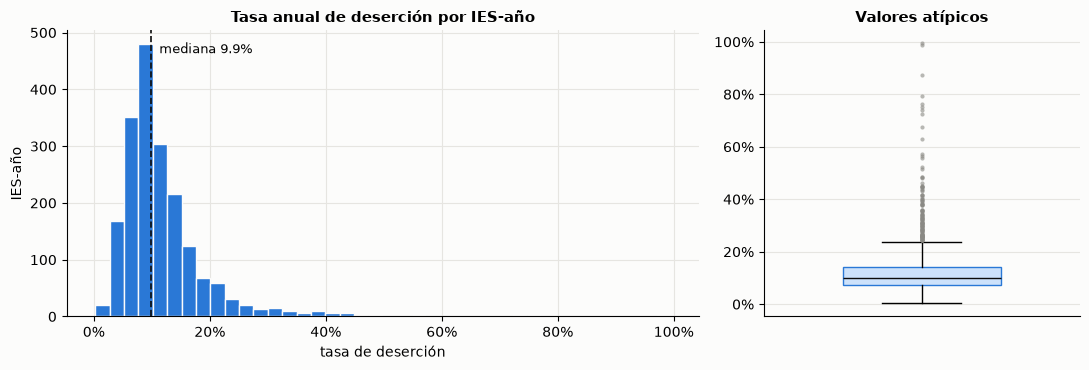

,0.05,0.25,0.50,0.75,0.95
tasa_desercion,0.043,0.073,0.099,0.141,0.261


Asimetría: 3.84 · IES-año con tasa > 50 %: 15


In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [2, 1]})
ejes[0].hist(df["tasa_desercion"], bins=40, color=AZUL, edgecolor="#fcfcfb", linewidth=1)
mediana = df["tasa_desercion"].median()
ejes[0].axvline(mediana, color="#0b0b0b", lw=1.2, ls="--")
ejes[0].annotate(f"mediana {mediana:.1%}", (mediana, ejes[0].get_ylim()[1] * 0.92), xytext=(6, 0),
                 textcoords="offset points", fontsize=9)
ejes[0].set(title="Tasa anual de deserción por IES-año", xlabel="tasa de deserción", ylabel="IES-año")
ejes[0].xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")

ejes[1].boxplot(df["tasa_desercion"], orientation="vertical", widths=0.5, patch_artist=True,
                boxprops=dict(facecolor="#cde2fb", edgecolor=AZUL), medianprops=dict(color="#0b0b0b"),
                flierprops=dict(marker="o", markersize=3, markerfacecolor=GRIS, markeredgecolor="none", alpha=0.6))
ejes[1].set(title="Valores atípicos", xticks=[])
ejes[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout()
plt.show()

q = df["tasa_desercion"].quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(3)
display(q.to_frame("tasa_desercion").T)
print(f"Asimetría: {stats.skew(df['tasa_desercion']):.2f} · IES-año con tasa > 50 %: {(df['tasa_desercion'] > 0.5).sum()}")

In [6]:
# Las tasas muy altas suelen venir de IES pequeñas o de crecimiento rápido (el denominador es la matrícula de hace un año)
altas = df[df["tasa_desercion"] > 0.5].copy()
display(altas[["cod_ies", "anio", "departamento", "naturaleza", "tasa_desercion", "matriculados_ies_t2"]]
        .sort_values("tasa_desercion", ascending=False).head(10).round(3))
print("Matrícula t-2 mediana de las IES-año con tasa > 50 %:", altas["matriculados_ies_t2"].median(),
      "· del resto:", df.loc[df["tasa_desercion"] <= 0.5, "matriculados_ies_t2"].median())

,cod_ies,anio,departamento,naturaleza,tasa_desercion,matriculados_ies_t2
1882,9903,2019,"Bogota, D.C.",Privada,0.994,146.0
1883,9903,2020,"Bogota, D.C.",Privada,0.987,184.0
1879,9903,2016,"Bogota, D.C.",Privada,0.873,NaN
1881,9903,2018,"Bogota, D.C.",Privada,0.792,278.0
1488,3807,2021,Antioquia,Privada,0.765,254.0
1691,4808,2021,Valle Del Cauca,Privada,0.753,374.0
1741,4826,2016,Bolivar,Privada,0.742,NaN
1867,9899,2020,"Bogota, D.C.",Privada,0.725,1971.0
1704,4812,2017,"Bogota, D.C.",Privada,0.676,276.0
1878,9903,2015,"Bogota, D.C.",Privada,0.630,NaN


Matrícula t-2 mediana de las IES-año con tasa > 50 %: 276.0 · del resto: 3817.0


### Efecto del denominador mínimo (`min_matriculados_t2`)

La tasa es desertores sobre la matrícula de dos semestres atrás; con denominadores chicos es muy inestable. El ETL excluye las
IES-año cuyo denominador (promedio de los dos semestres de t-2) es menor que `min_matriculados_t2` de `config.yaml`. Aquí se
compara el dataset sin ese filtro (mínimo = 0) con el que se usa.

Mínimo de matrícula t-2: 100
IES-año sin filtro: 2,148 · con el mínimo: 2,051 · eliminadas: 97 (4.5%) · IES que desaparecen por completo: 9


Después se excluyen 9 IES-año por posible cierre (excluir_posible_cierre = True) y 114 por calidad (inconsistencia entre fuentes, régimen especial y, si `excluir_sena`, SENA): dataset final 1,928 filas, 295 IES


,sin filtro,con el mínimo,eliminadas por el mínimo,dataset final
filas,2148.000,2051.000,97.000,1928.000
media,0.129,0.122,0.279,0.120
mediana,0.100,0.098,0.248,0.099
desv. est.,0.106,0.093,0.202,0.087
p95,0.311,0.277,0.729,0.261
máximo,0.994,0.994,0.917,0.994
asimetría,3.510,3.767,1.200,3.839
filas con tasa > 50 %,33.000,20.000,13.000,15.000


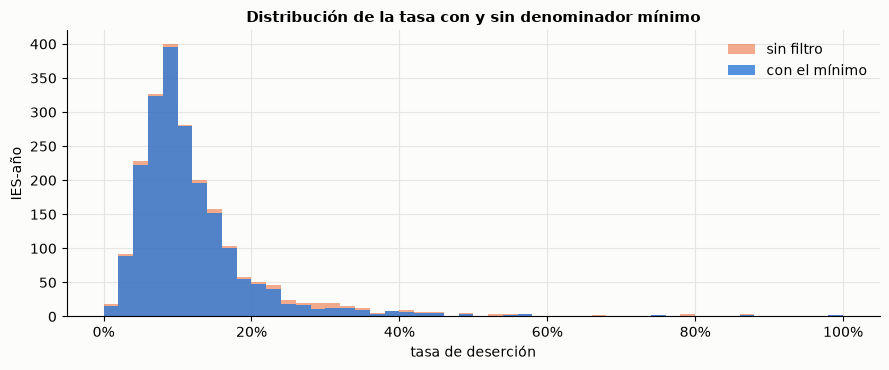

In [7]:
from src.extract.spadies import leer_spadies

minimo = cfg.get("min_matriculados_t2", 100)
# Las rutas de config.yaml son relativas a la raíz del proyecto, no a notebooks/
spadies_abs = {k: (str(ROOT / v) if k in ("archivo", "nacional") else v) for k, v in cfg["spadies"].items()}
base = {**cfg, "spadies": spadies_abs, "excluir_posible_cierre": False}  # el efecto de los posibles cierres se ve aparte
ventana = lambda t: t[t["anio"].between(min(cfg["anios"]), max(cfg["anios"]))]
sin_filtro = ventana(leer_spadies({**base, "min_matriculados_t2": 0}, []))
con_minimo = ventana(leer_spadies({**base, "min_matriculados_t2": minimo}, []))
llave = ["cod_ies", "anio"]
quitadas = sin_filtro.merge(con_minimo[llave], on=llave, how="left", indicator=True).query("_merge == 'left_only'")

print(f"Mínimo de matrícula t-2: {minimo}")
print(f"IES-año sin filtro: {len(sin_filtro):,} · con el mínimo: {len(con_minimo):,} · eliminadas: {len(quitadas):,} "
      f"({len(quitadas) / len(sin_filtro):.1%}) · IES que desaparecen por completo: "
      f"{sin_filtro['cod_ies'].nunique() - con_minimo['cod_ies'].nunique()}")
# Efecto de los posibles cierres: la misma lectura del mínimo, con la opción de la configuración
con_cierre = ventana(leer_spadies({**base, "min_matriculados_t2": minimo,
                                   "excluir_posible_cierre": cfg.get("excluir_posible_cierre", True)}, []))
n_cierre = len(con_minimo) - len(con_cierre)
calidad = pd.read_csv(ROOT / cfg["rutas"]["reports"] / "exclusiones_calidad.csv", dtype={"cod_ies": str})
n_calidad = int(calidad["excluida"].sum())
print(f"Después se excluyen {n_cierre:,} IES-año por posible cierre (excluir_posible_cierre = {cfg.get('excluir_posible_cierre', True)}) "
      f"y {n_calidad:,} por calidad (inconsistencia entre fuentes, régimen especial y, si `excluir_sena`, SENA): "
      f"dataset final {len(df):,} filas, {df['cod_ies'].nunique()} IES")
assert len(con_minimo) - n_cierre - n_calidad == len(df), "las exclusiones no cuadran con el dataset final"

def resumen(serie):
    return pd.Series({"filas": len(serie), "media": serie.mean(), "mediana": serie.median(), "desv. est.": serie.std(),
                      "p95": serie.quantile(0.95), "máximo": serie.max(), "asimetría": stats.skew(serie),
                      "filas con tasa > 50 %": int((serie > 0.5).sum())})

comparacion = pd.DataFrame({"sin filtro": resumen(sin_filtro["tasa_desercion"]),
                            "con el mínimo": resumen(con_minimo["tasa_desercion"]),
                            "eliminadas por el mínimo": resumen(quitadas["tasa_desercion"]),
                            "dataset final": resumen(df["tasa_desercion"])})
display(comparacion.round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.linspace(0, 1, 51)
ax.hist(sin_filtro["tasa_desercion"], bins=bins, color=NARANJA, alpha=0.55, label="sin filtro")
ax.hist(con_minimo["tasa_desercion"], bins=bins, color=AZUL, alpha=0.8, label="con el mínimo")
ax.set(title="Distribución de la tasa con y sin denominador mínimo", xlabel="tasa de deserción", ylabel="IES-año")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### IES-año con tasa > 50 % y posible cierre

`reports/tasas_altas.csv` (lo escribe el pipeline) lista las IES-año con tasa mayor que `umbral_tasa_alta` tras el denominador
mínimo, con el denominador de SPADIES, la matrícula t-2 de SNIES y el último periodo que reportó la IES. `posible_cierre` marca
las filas que caen en los 2 semestres previos al último reporte (o en ese reporte) de una IES que dejó de reportar antes del final del archivo.

In [8]:
tasas_altas = pd.read_csv(ROOT / cfg["rutas"]["reports"] / "tasas_altas.csv", dtype={"cod_ies": str})
display(tasas_altas.round({"tasa_desercion": 3, "matriculados_t2_spadies": 0}))
print(f"{len(tasas_altas)} IES-año de {tasas_altas['cod_ies'].nunique()} IES · en ventana de posible cierre: "
      f"{int(tasas_altas['posible_cierre'].sum())} · IES con último reporte 2024-2 (siguen activas): "
      f"{(tasas_altas.drop_duplicates('cod_ies')['ultimo_periodo'] == '2024-2').sum()} de {tasas_altas['cod_ies'].nunique()}")

,cod_ies,nombre,anio,tasa_desercion,matriculados_t2_spadies,ultimo_periodo,posible_cierre,matriculados_t2_snies,ratio_spadies_snies,inconsistencia_fuentes,regimen_especial,es_sena
0,2106,DIRECCION NACIONAL DE ESCUELAS,2016,0.873,1271.0,2024-2,False,NaN,NaN,False,True,False
1,2824,CORPORACION UNIVERSITARIA DE COLOMBIA IDEAS,2017,0.575,208.0,2022-2,False,905.0,0.229834,True,False,False
2,3114,ESCUELA NAVAL DE SUBOFICIALES ARC BARRANQUILLA,2018,0.889,294.0,2024-2,False,130.0,2.261538,False,True,False
3,3716,TECNOLOGICA FITEC,2015,0.572,752.0,2024-2,False,NaN,NaN,False,False,False
4,3807,ESCUELA DE TECNOLOGIAS DE ANTIOQUIA -ETA-,2021,0.765,164.0,2024-2,False,254.0,0.643701,False,False,False
5,3828,CORPORACIÓN TECNOLÓGICA DE EDUCACIÓN SUPERIOR ...,2018,0.524,169.0,2022-2,False,115.0,1.469565,False,False,False
6,4808,CORPORACION REGIONAL DE EDUCACION SUPERIOR-CRE...,2021,0.753,150.0,2024-2,False,374.0,0.401070,False,False,False
7,4812,CORPORACION DE EDUCACION SUPERIOR SURAMERICA,2017,0.676,380.0,2024-2,False,276.0,1.376812,False,False,False
8,4826,CORPORACION UNIVERSITARIA REGIONAL DEL CARIBE ...,2015,0.558,325.0,2022-2,False,NaN,NaN,False,False,False
9,4826,CORPORACION UNIVERSITARIA REGIONAL DEL CARIBE ...,2016,0.742,234.0,2022-2,False,NaN,NaN,False,False,False


20 IES-año de 13 IES · en ventana de posible cierre: 0 · IES con último reporte 2024-2 (siguen activas): 10 de 13


### Exclusiones por calidad: inconsistencia entre fuentes y régimen especial

- `ratio_spadies_snies` = denominador de SPADIES (matrícula t-2) / matrícula SNIES t-2 de la IES; `inconsistencia_fuentes` se activa
  si el ratio es > 3 o < 1/3, o si SNIES no tiene dato dentro de su cobertura (SNIES por programa empieza en 2015: para los años
  cuyo t-2 es anterior no se marca, porque si no se perderían 2015 y 2016 enteros).
- `regimen_especial`: escuelas militares y policiales, por lista explícita de 16 códigos SNIES (2106, 2901–2906, 3114, 3901, 3902, 9101–9105, 9107); 9108 y 9109 no son militares y quedan fuera.
- `es_sena`: el SENA (9110); se marca pero no se excluye salvo que `excluir_sena` sea true.
- `excluir_inconsistencias` y `excluir_regimen_especial` (por defecto activas) las sacan del dataset, y `excluir_sena` (apagada) también al SENA; el detalle está en `reports/exclusiones_calidad.csv`.

In [9]:
excluye = {"inconsistencia_fuentes": cfg.get("excluir_inconsistencias", True), "regimen_especial": cfg.get("excluir_regimen_especial", True),
           "es_sena": cfg.get("excluir_sena", False)}
resumen_calidad = pd.DataFrame({
    "IES-año marcadas": [int(calidad[c].sum()) for c in excluye] + [len(calidad)],
    "IES": [calidad.loc[calidad[c], "cod_ies"].nunique() for c in excluye] + [calidad["cod_ies"].nunique()],
    "IES-año excluidas": [int((calidad[c] & e).sum()) for c, e in excluye.items()] + [n_calidad],
}, index=list(excluye) + ["unión (filas con alguna bandera)"])
display(resumen_calidad)

# Qué pasa con las tasas > 50 %: cuántas de las 20 filas elimina cada bandera
altas = pd.read_csv(ROOT / cfg["rutas"]["reports"] / "tasas_altas.csv", dtype={"cod_ies": str})
altas[["inconsistencia_fuentes", "regimen_especial"]] = altas[["inconsistencia_fuentes", "regimen_especial"]].fillna(False).astype(bool)
print(f"Tasas > 50 % tras el mínimo: {len(altas)}")
print(f"  eliminadas por inconsistencia_fuentes: {int(altas['inconsistencia_fuentes'].sum())}")
print(f"  eliminadas por regimen_especial: {int(altas['regimen_especial'].sum())}")
print(f"  eliminadas por alguna: {int((altas['inconsistencia_fuentes'] | altas['regimen_especial']).sum())} · quedan {int((~(altas['inconsistencia_fuentes'] | altas['regimen_especial'])).sum())}")

print()
print("Ratio SPADIES / SNIES en el dataset final (IES-año con ambos datos):")
display(df["ratio_spadies_snies"].describe().round(2).to_frame("ratio").T)

,IES-año marcadas,IES,IES-año excluidas
inconsistencia_fuentes,37,22,37
regimen_especial,85,13,85
es_sena,7,1,0
unión (filas con alguna bandera),121,33,114


Tasas > 50 % tras el mínimo: 20
  eliminadas por inconsistencia_fuentes: 3
  eliminadas por regimen_especial: 2
  eliminadas por alguna: 5 · quedan 15

Ratio SPADIES / SNIES en el dataset final (IES-año con ambos datos):


,count,mean,std,min,25%,50%,75%,max
ratio,1369.0,0.9,0.21,0.35,0.79,0.88,0.97,2.63


### Composición oficial / privada antes y después de las exclusiones

Tres etapas: **sin filtro** (todas las IES con tasa anual en 2015–2021), **tras el denominador mínimo y los posibles cierres** y
**dataset final** (además sin inconsistencias entre fuentes ni régimen especial). La naturaleza sale del catálogo de SNIES.

In [10]:
from src.integrate.build import sede_por_ies

sede, _ = sede_por_ies(pd.read_csv(ROOT / cfg["rutas"]["interim"] / "snies_catalogo.csv", dtype=str))
naturaleza_ies = sede.set_index("cod_ies")["sector"].map({"1": "Oficial", "2": "Privada"})

def composicion(tabla):
    nat = tabla["cod_ies"].map(naturaleza_ies)
    por_ies = nat.groupby(tabla["cod_ies"]).first().value_counts()
    por_fila = nat.value_counts()
    return pd.Series({"IES": tabla["cod_ies"].nunique(), "IES oficiales": por_ies.get("Oficial", 0), "IES privadas": por_ies.get("Privada", 0),
                      "% IES oficiales": 100 * por_ies.get("Oficial", 0) / tabla["cod_ies"].nunique(),
                      "IES-año": len(tabla), "IES-año oficiales": por_fila.get("Oficial", 0), "IES-año privadas": por_fila.get("Privada", 0),
                      "% IES-año oficiales": 100 * por_fila.get("Oficial", 0) / len(tabla)})

etapas = pd.DataFrame({"sin filtro": composicion(sin_filtro), "tras mínimo y cierre": composicion(con_cierre),
                       "dataset final": composicion(df)})
display(etapas.round(1))
perdidas = sin_filtro.drop_duplicates("cod_ies").loc[~sin_filtro.drop_duplicates("cod_ies")["cod_ies"].isin(df["cod_ies"]), "cod_ies"]
print("IES que salen entre la primera y la última etapa, por naturaleza:", perdidas.map(naturaleza_ies).value_counts().to_dict())

,sin filtro,tras mínimo y cierre,dataset final
IES,321.0,311.0,295.0
IES oficiales,95.0,94.0,79.0
IES privadas,226.0,217.0,216.0
% IES oficiales,29.6,30.2,26.8
IES-año,2148.0,2042.0,1928.0
IES-año oficiales,637.0,615.0,526.0
IES-año privadas,1511.0,1427.0,1402.0
% IES-año oficiales,29.7,30.1,27.3


IES que salen entre la primera y la última etapa, por naturaleza: {'Oficial': 16, 'Privada': 10}


### ¿Es el SENA atípico? (por tamaño o por tasa)

El SENA (código 9110) está en el dataset (`es_sena`; `excluir_sena` apagada). Se compara su matrícula de referencia (SNIES, t-2) y su
tasa con la distribución de las demás IES del mismo año.

In [11]:
sena = df[df["es_sena"]].copy()
otras = df[~df["es_sena"]]
filas = []
for anio, g in sena.groupby("anio"):
    resto = otras[otras["anio"] == anio]
    mat = g["matriculados_ies_t2"].iloc[0]
    filas.append({"anio": anio, "tasa SENA": g["tasa_desercion"].iloc[0],
                  "percentil de la tasa": 100 * (resto["tasa_desercion"] < g["tasa_desercion"].iloc[0]).mean(),
                  "matrícula t-2 SENA": mat,
                  "mediana de las demás": resto["matriculados_ies_t2"].median(),
                  "máxima de las demás": resto["matriculados_ies_t2"].max(),
                  "veces la mediana": mat / resto["matriculados_ies_t2"].median() if pd.notna(mat) else np.nan,
                  "veces la mayor otra IES": mat / resto["matriculados_ies_t2"].max() if pd.notna(mat) else np.nan})
display(pd.DataFrame(filas).set_index("anio").round(2))
tasa_sena, tasa_resto = sena["tasa_desercion"], otras["tasa_desercion"]
print(f"Tasa del SENA: mediana {tasa_sena.median():.1%} (rango {tasa_sena.min():.1%}–{tasa_sena.max():.1%}) frente a {tasa_resto.median():.1%} "
      f"de las demás IES (p5–p95: {tasa_resto.quantile(.05):.1%}–{tasa_resto.quantile(.95):.1%}).")
print(f"Matrícula t-2 del SENA: {sena['matriculados_ies_t2'].median():,.0f} frente a una mediana de {otras['matriculados_ies_t2'].median():,.0f} "
      f"y un máximo de {otras['matriculados_ies_t2'].max():,.0f} en las demás.")

,tasa SENA,percentil de la tasa,matrícula t-2 SENA,mediana de las demás,máxima de las demás,veces la mediana,veces la mayor otra IES
anio,,,,,,,
2015,0.08,28.78,NaN,NaN,NaN,NaN,NaN
2016,0.17,82.80,NaN,NaN,NaN,NaN,NaN
2017,0.13,64.84,425847.0,3671.0,91407.0,116.00,4.66
2018,0.14,78.62,430690.0,3788.0,106088.0,113.70,4.06
2019,0.11,57.51,467643.0,3642.0,118018.0,128.40,3.96
2020,0.12,67.65,463653.0,3767.0,122581.0,123.08,3.78
2021,0.12,70.00,431109.0,3835.0,110263.0,112.41,3.91


Tasa del SENA: mediana 12.4% (rango 8.2%–16.7%) frente a 9.8% de las demás IES (p5–p95: 4.3%–26.1%).
Matrícula t-2 del SENA: 431,109 frente a una mediana de 3,766 y un máximo de 122,581 en las demás.


**Decisión.** El SENA se mantiene (`excluir_sena: false`) porque su tasa no es atípica; el tamaño se maneja con la transformación
logarítmica `log_matriculados_ies_t2 = log1p(matriculados_ies_t2)`, que es la versión explicativa (la bruta queda en el dataset pero
fuera de las explicativas por defecto). Abajo se ve cuánto comprime el logaritmo la asimetría y el efecto de quitar al SENA
(análisis de sensibilidad: `cargar_dataset(cfg, excluir_sena=True)` o `modelado.excluir_sena: true`).

escenario,con SENA (por defecto),sin SENA (sensibilidad)
filas,1369.000,1364.000
IES,289.000,288.000
asimetría matrícula bruta,13.514,5.081
asimetría log1p,-0.215,-0.348
rho Spearman bruta-tasa,-0.352,-0.358
rho Spearman log-tasa,-0.352,-0.358
tasa mediana,0.097,0.097
tasa media,0.117,0.117


Puntaje z del SENA (2017) frente a las demás IES: matrícula bruta 40 desviaciones; log1p 3.5 desviaciones


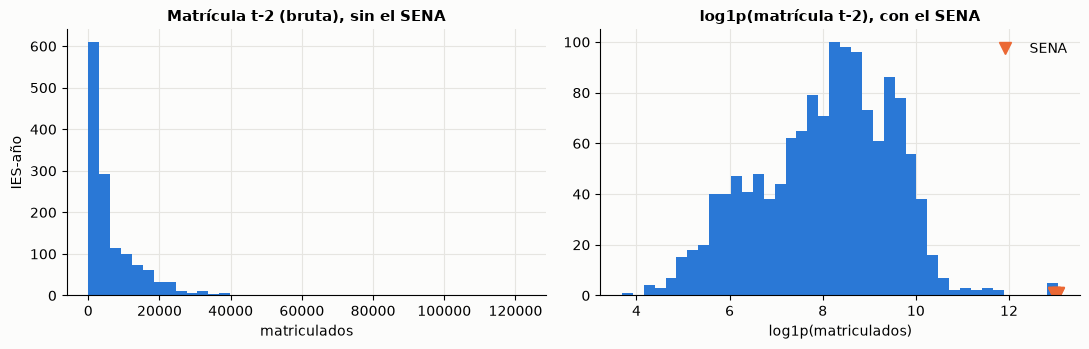

In [12]:
con_mat = df.dropna(subset=["matriculados_ies_t2"])
sin_sena = con_mat[~con_mat["es_sena"]]
def z(serie, valor):
    return (valor - serie.mean()) / serie.std()

fila = lambda nombre, d: {"escenario": nombre, "filas": len(d), "IES": d["cod_ies"].nunique(),
                          "asimetría matrícula bruta": stats.skew(d["matriculados_ies_t2"]),
                          "asimetría log1p": stats.skew(d["log_matriculados_ies_t2"]),
                          "rho Spearman bruta-tasa": d["matriculados_ies_t2"].corr(d["tasa_desercion"], method="spearman"),
                          "rho Spearman log-tasa": d["log_matriculados_ies_t2"].corr(d["tasa_desercion"], method="spearman"),
                          "tasa mediana": d["tasa_desercion"].median(), "tasa media": d["tasa_desercion"].mean()}
sens = pd.DataFrame([fila("con SENA (por defecto)", con_mat), fila("sin SENA (sensibilidad)", sin_sena)]).set_index("escenario")
display(sens.round(3).T)

fila_sena = con_mat[con_mat["es_sena"]].iloc[0]
print(f"Puntaje z del SENA ({int(fila_sena['anio'])}) frente a las demás IES: matrícula bruta {z(sin_sena['matriculados_ies_t2'], fila_sena['matriculados_ies_t2']):.0f} desviaciones; "
      f"log1p {z(sin_sena['log_matriculados_ies_t2'], fila_sena['log_matriculados_ies_t2']):.1f} desviaciones")

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6))
ejes[0].hist(sin_sena["matriculados_ies_t2"], bins=40, color=AZUL)
ejes[0].set(title="Matrícula t-2 (bruta), sin el SENA", xlabel="matriculados", ylabel="IES-año")
ejes[1].hist(con_mat["log_matriculados_ies_t2"], bins=40, color=AZUL)
sena_log = con_mat.loc[con_mat["es_sena"], "log_matriculados_ies_t2"]
ejes[1].plot(sena_log, [1] * len(sena_log), "v", color=NARANJA, markersize=9, label="SENA")
ejes[1].set(title="log1p(matrícula t-2), con el SENA", xlabel="log1p(matriculados)")
ejes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

## 3. Evolución 2015–2021

,mediana,media,p25,p75,n
anio,,,,,
2015,0.106,0.133,0.077,0.155,279
2016,0.100,0.124,0.077,0.140,280
2017,0.111,0.130,0.080,0.150,274
2018,0.098,0.117,0.074,0.138,277
2019,0.096,0.111,0.071,0.128,274
2020,0.094,0.115,0.073,0.130,273
2021,0.091,0.113,0.065,0.138,271


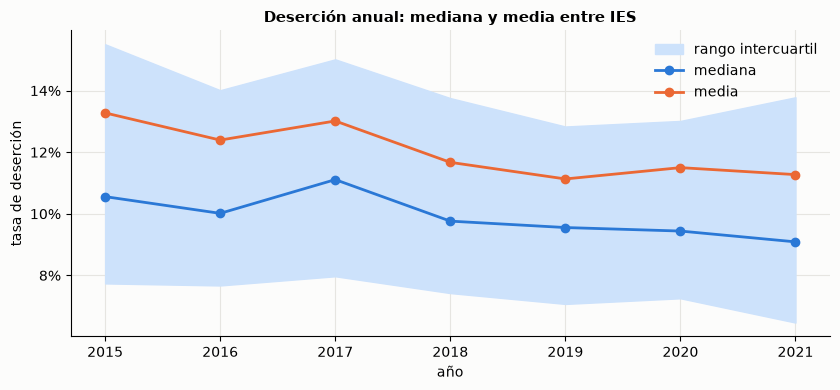

In [13]:
por_anio = df.groupby("anio")["tasa_desercion"].agg(
    mediana="median", media="mean", p25=lambda s: s.quantile(0.25), p75=lambda s: s.quantile(0.75), n="size")
display(por_anio.round(3))

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.fill_between(por_anio.index, por_anio["p25"], por_anio["p75"], color="#cde2fb", label="rango intercuartil")
ax.plot(por_anio.index, por_anio["mediana"], color=AZUL, lw=2, marker="o", markersize=6, label="mediana")
ax.plot(por_anio.index, por_anio["media"], color=NARANJA, lw=2, marker="o", markersize=6, label="media")
ax.set(title="Deserción anual: mediana y media entre IES", xlabel="año", ylabel="tasa de deserción")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

## 4. Oficial frente a privada

,size,median,mean,std
naturaleza,,,,
Oficial,526,0.087,0.106,0.065
Privada,1402,0.102,0.126,0.093


Mann-Whitney U (oficial vs. privada): p = 7.51e-09. Las observaciones de una misma IES no son independientes, así que el valor p es solo orientativo.


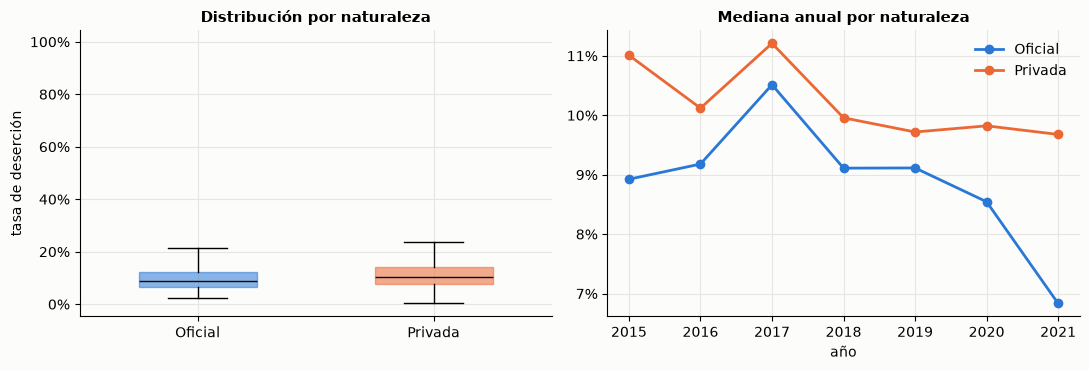

In [14]:
resumen = df.groupby("naturaleza")["tasa_desercion"].agg(["size", "median", "mean", "std"]).round(3)
display(resumen)
oficial = df.loc[df["naturaleza"] == "Oficial", "tasa_desercion"]
privada = df.loc[df["naturaleza"] == "Privada", "tasa_desercion"]
u, p = stats.mannwhitneyu(oficial, privada)
print(f"Mann-Whitney U (oficial vs. privada): p = {p:.3g}. Las observaciones de una misma IES no son independientes, "
      "así que el valor p es solo orientativo.")

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
ejes[0].boxplot([oficial, privada], tick_labels=["Oficial", "Privada"], widths=0.5, patch_artist=True,
                medianprops=dict(color="#0b0b0b"),
                flierprops=dict(marker="o", markersize=3, markeredgecolor="none", alpha=0.5))
for caja, color in zip(ejes[0].patches, [AZUL, NARANJA]):
    caja.set(facecolor=color, alpha=0.55, edgecolor=color)
ejes[0].set(title="Distribución por naturaleza", ylabel="tasa de deserción")
ejes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")

serie = df.groupby(["anio", "naturaleza"])["tasa_desercion"].median().unstack()
for nombre, color in (("Oficial", AZUL), ("Privada", NARANJA)):
    ejes[1].plot(serie.index, serie[nombre], color=color, lw=2, marker="o", markersize=6, label=nombre)
ejes[1].set(title="Mediana anual por naturaleza", xlabel="año")
ejes[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ejes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

## 5. Por departamento (sede de la IES)

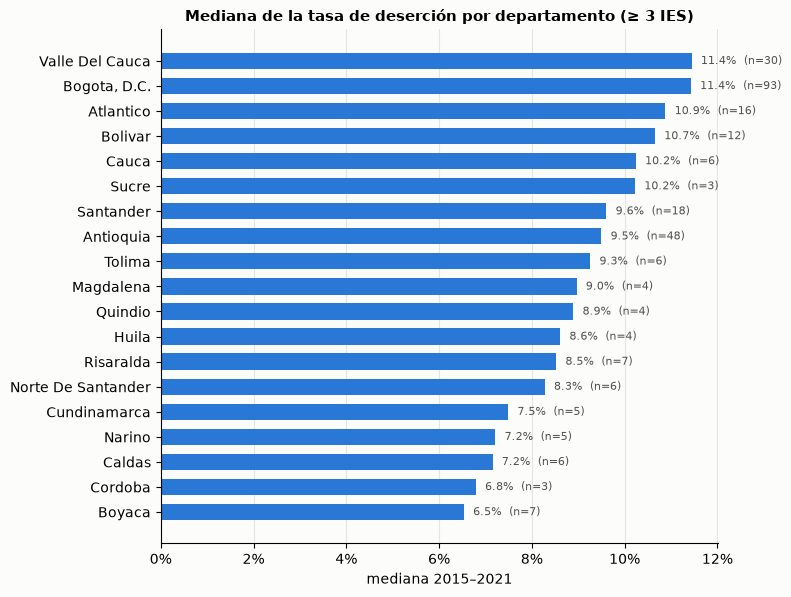

27 departamentos con IES en el dataset; 8 tienen menos de 3 y no se grafican.


In [15]:
dep = df.groupby("departamento").agg(ies=("cod_ies", "nunique"), mediana=("tasa_desercion", "median"),
                                       media=("tasa_desercion", "mean")).sort_values("mediana")
# Con pocas IES la mediana departamental es muy inestable: se grafican solo los departamentos con 3 o más
grande = dep[dep["ies"] >= 3]
fig, ax = plt.subplots(figsize=(8, max(3, 0.32 * len(grande))))
ax.barh(grande.index, grande["mediana"], color=AZUL, height=0.65)
for y, (m, n) in enumerate(zip(grande["mediana"], grande["ies"])):
    ax.text(m + 0.002, y, f"{m:.1%}  (n={n})", va="center", fontsize=8, color="#52514e")
ax.set(title="Mediana de la tasa de deserción por departamento (≥ 3 IES)", xlabel="mediana 2015–2021")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
print(f"{len(dep)} departamentos con IES en el dataset; {len(dep) - len(grande)} tienen menos de 3 y no se grafican.")

## 6. Valores nulos por fuente

,% nulos promedio,% nulos máximo,variables
fuente,,,
Saber 11 (ICFES),28.3,28.3,5
SPADIES / SNIES,14.5,29.0,2
SNIES (MEN),7.2,29.0,8
TerriData (DNP),5.9,29.1,23
ETL,0.0,0.0,3
SPADIES (MEN),0.0,0.0,2


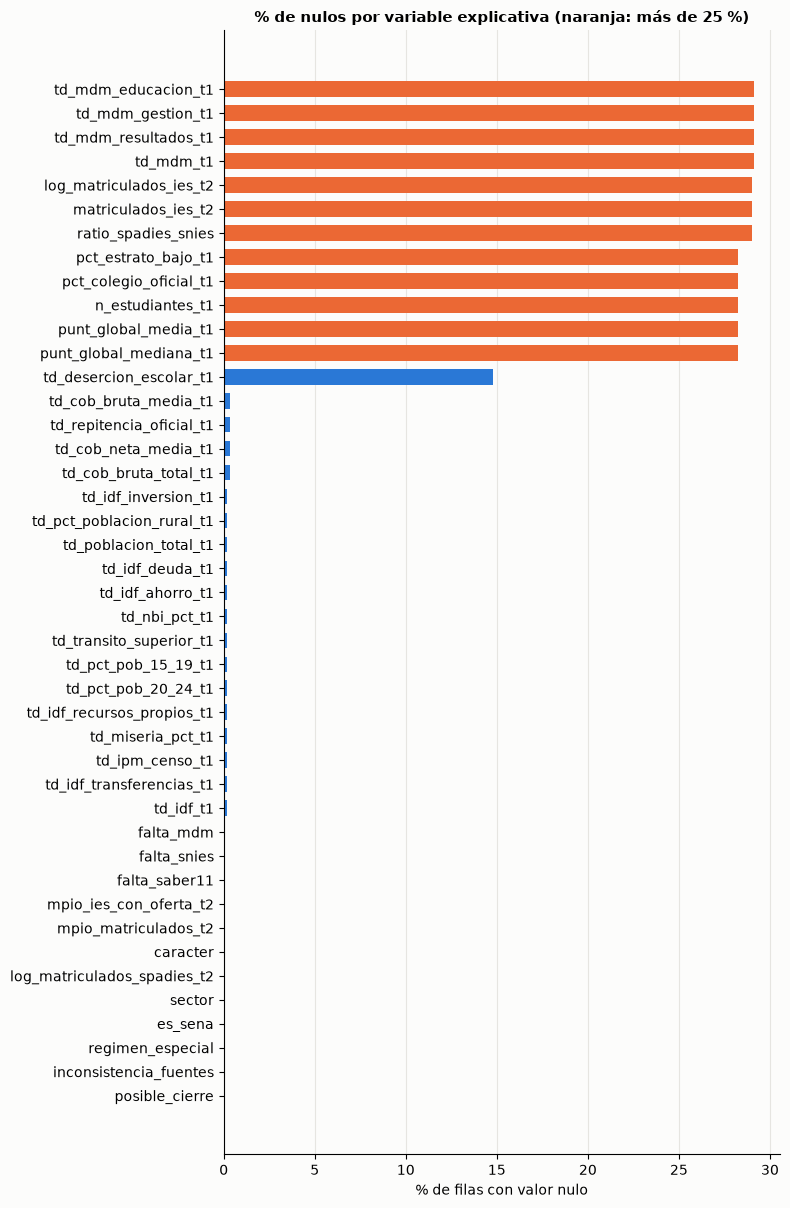

In [16]:
fuentes, _ = describir_columnas(list(df.columns))
explicativas = [c for c in df.columns if c in fuentes and c not in ("tasa_desercion", "cod_ies", "cod_divipola_mpio", "anio")]
nulos = (df[explicativas].isna().mean() * 100).rename("% nulos").to_frame()
nulos["fuente"] = [fuentes[c] for c in nulos.index]

por_fuente = nulos.groupby("fuente")["% nulos"].agg(["mean", "max", "size"]).round(1)
por_fuente.columns = ["% nulos promedio", "% nulos máximo", "variables"]
display(por_fuente.sort_values("% nulos promedio", ascending=False))

fig, ax = plt.subplots(figsize=(8, 0.26 * len(nulos) + 1))
orden = nulos.sort_values("% nulos")
ax.barh(orden.index, orden["% nulos"], color=[NARANJA if v > 25 else AZUL for v in orden["% nulos"]], height=0.65)
ax.set(title="% de nulos por variable explicativa (naranja: más de 25 %)", xlabel="% de filas con valor nulo")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [17]:
# Variables descartadas por exceso de nulos y otras observaciones de calidad de la última corrida
log = (ROOT / cfg["rutas"]["reports"] / "etl_log.md").read_text(encoding="utf-8")
for linea in log.splitlines():
    if "descartada(s) por superar" in linea or "sin municipio sede" in linea or "cobertura incompleta" in linea:
        print(linea[:400])

- **Otras limitaciones** ya documentadas: 28,5 % de nulos en Saber 11 (años con cobertura incompleta), `matriculados_ies_t2` casi coincide con el denominador de la tasa, cambio de base de las proyecciones de población entre 2017 y 2018 (ver abajo) y muchas variables territoriales colineales.
  - **Saber 11**: se excluyen los años 2018, 2020 y 2021 (cobertura incompleta del calendario A); con t-1 faltan **2019 y 2021** (100 %).
- Saber 11: cobertura incompleta en los años [2018, 2020, 2021] (falta el calendario A); se excluyen, por lo que las variables Saber 11 de los años [2019, 2021, 2022] quedan nulas
- TerriData: 5 de 28 variable(s) descartada(s) por superar 50% de nulos tras el rezago: td_cob_superior_t1 (58%), td_cotizantes_t1 (57%), td_empresas_empleo_formal_t1 (57%), td_ocupacion_formal_pct_t1 (57%), td_tgp_t1 (65%)
- TerriData: 1 de 295 IES sin municipio sede en TerriData (4106→88001); quedan con sus variables td_* nulas


**Lectura.** Los nulos de `matriculados_ies_t2` en 2015–2016 son esperados (la matrícula por programa de SNIES empieza en 2015
y el rezago es de dos años). Las de Saber 11 vienen de los años con cobertura incompleta del calendario A, que el ETL excluye
en vez de usar una muestra sesgada.

### Nulos por bloques de años, no al azar

Los nulos de las explicativas no son dispersos: vienen en **bloques de años** por la forma en que se construye cada fuente. El ETL los
marca con tres indicadores 0/1 (`falta_saber11`, `falta_mdm`, `falta_snies`) para que el modelo pueda distinguirlos:

- **MDM** (medición de desempeño municipal) empieza en 2016, así que con el rezago t-1 faltan **2015 y 2016**.
- **SNIES** (matrícula por programa) empieza en 2015, así que con el rezago t-2 faltan **2015 y 2016**.
- **Saber 11** pierde los años cuya cobertura del calendario A es incompleta (2018, 2020 y 2021), así que con el rezago t-1 faltan **2019 y 2021**.

anio,2015,2016,2017,2018,2019,2020,2021
% de IES-año sin dato,,,,,,,
Saber 11,0.0,0.0,0.0,0.0,100.0,0.0,100.0
MDM,100.0,100.0,0.0,0.0,0.0,0.0,0.0
SNIES (matrícula t-2),100.0,100.0,0.0,0.0,0.0,0.0,0.0


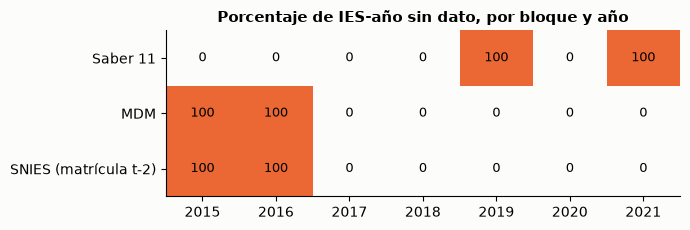

In [18]:
bloques = {"Saber 11": "falta_saber11", "MDM": "falta_mdm", "SNIES (matrícula t-2)": "falta_snies"}
por_anio = pd.DataFrame({nombre: 100 * df.groupby("anio")[col].mean() for nombre, col in bloques.items()}).T.round(0)
por_anio.index.name = "% de IES-año sin dato"
display(por_anio)

fig, ax = plt.subplots(figsize=(7, 2.4))
im = ax.imshow(por_anio.values, cmap=LinearSegmentedColormap.from_list("nulos", ["#fcfcfb", "#eb6834"]), vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(por_anio.columns)), por_anio.columns)
ax.set_yticks(range(len(por_anio)), por_anio.index)
for i in range(por_anio.shape[0]):
    for j in range(por_anio.shape[1]):
        ax.text(j, i, f"{por_anio.values[i, j]:.0f}", ha="center", va="center", fontsize=9)
ax.grid(False)
ax.set_title("Porcentaje de IES-año sin dato, por bloque y año")
plt.tight_layout()
plt.show()

**Efecto en la partición temporal.** Con entrenamiento 2015–2019 y prueba 2020–2021: MDM y SNIES faltan solo en el entrenamiento (2015–2016) y la
prueba los tiene completos, de modo que el modelo aprende con una parte de filas imputadas pero se evalúa sobre datos completos; Saber 11 falta en
2019 (entrenamiento) y en **2021 (la mitad de la prueba)**, así que la mitad de la prueba se predice con Saber 11 imputado por la mediana del entrenamiento. La
sensibilidad `ventana_modelado = (2017, 2021)` quita los años donde faltan MDM y SNIES; entrena con 2017–2019.

In [19]:
from src.modelado.particion import particion_temporal

filas = []
for ventana in ((2015, 2021), (2017, 2021)):
    sub = df[df["anio"].between(*ventana)].reset_index(drop=True)
    entrena, prueba = particion_temporal(sub, 2019)
    for etapa, idx in (("entrenamiento", entrena), ("prueba", prueba)):
        parte = sub.iloc[idx]
        filas.append({"ventana": f"{ventana[0]}–{ventana[1]}", "conjunto": f"{etapa} ({int(parte['anio'].min())}–{int(parte['anio'].max())})", "filas": len(parte),
                      "% sin Saber 11": 100 * parte["falta_saber11"].mean(), "% sin MDM": 100 * parte["falta_mdm"].mean(),
                      "% sin SNIES t-2": 100 * parte["falta_snies"].mean()})
display(pd.DataFrame(filas).set_index(["ventana", "conjunto"]).round(1))

filas  % sin Saber 11  % sin MDM  % sin SNIES t-2
ventana   conjunto                                                                    
2015–2021 entrenamiento (2015–2019)   1384            19.8       40.4             40.4
          prueba (2020–2021)           544            49.8        0.4              0.0
2017–2021 entrenamiento (2017–2019)    825            33.2        0.0              0.0
          prueba (2020–2021)           544            49.8        0.4              0.0

### Tamaño de la IES: denominador de SPADIES frente a matrícula de SNIES

`log_matriculados_spadies_t2` (log1p del denominador de la tasa; información de t-2, no fuga) es la variable de tamaño por defecto: viene
**completa en 2015–2021**. `log_matriculados_ies_t2` (SNIES) queda como alternativa: es casi la misma cosa (correlación ~0,99) pero falta en 2015–2016.
Las dos guardan una relación mecánica con la tasa porque el denominador es el de la propia tasa.

In [20]:
tam = df[["log_matriculados_spadies_t2", "log_matriculados_ies_t2", "tasa_desercion"]]
display(pd.DataFrame({"% nulos": 100 * tam.isna().mean(), "rho con la tasa": tam.corr(method="spearman")["tasa_desercion"],
                      "rho entre las dos": [tam.corr(method="spearman").loc["log_matriculados_spadies_t2", "log_matriculados_ies_t2"]] * 3}).iloc[:2].round(3))

,% nulos,rho con la tasa,rho entre las dos
log_matriculados_spadies_t2,0.000,-0.355,0.99
log_matriculados_ies_t2,28.994,-0.352,0.99


## 7. Correlaciones de las variables explicativas con la tasa

Fuera de las explicativas por defecto: ['td_poblacion_total_t1', 'ratio_spadies_snies', 'matriculados_ies_t2', 'log_matriculados_ies_t2']


,log_matriculados_spadies_t2,td_pct_poblacion_rural_t1,td_cob_bruta_total_t1,td_cob_bruta_media_t1,td_idf_deuda_t1,td_idf_transferencias_t1,td_mdm_educacion_t1,td_idf_inversion_t1,pct_colegio_oficial_t1,td_repitencia_oficial_t1,td_desercion_escolar_t1,pct_estrato_bajo_t1,td_mdm_resultados_t1,td_idf_recursos_propios_t1,td_transito_superior_t1,td_cob_neta_media_t1,punt_global_mediana_t1,td_pct_pob_15_19_t1,punt_global_media_t1,td_nbi_pct_t1,td_miseria_pct_t1,td_ipm_censo_t1,td_pct_pob_20_24_t1,td_mdm_t1,td_mdm_gestion_t1,mpio_matriculados_t2,td_idf_ahorro_t1,n_estudiantes_t1,mpio_ies_con_oferta_t2,td_idf_t1,privada
rho de Spearman,-0.355,-0.168,-0.16,-0.151,-0.136,-0.129,-0.123,-0.116,-0.111,-0.058,-0.049,-0.028,-0.026,-0.023,-0.022,-0.014,0.006,0.01,0.014,0.023,0.031,0.036,0.046,0.052,0.058,0.085,0.091,0.105,0.107,0.11,0.132


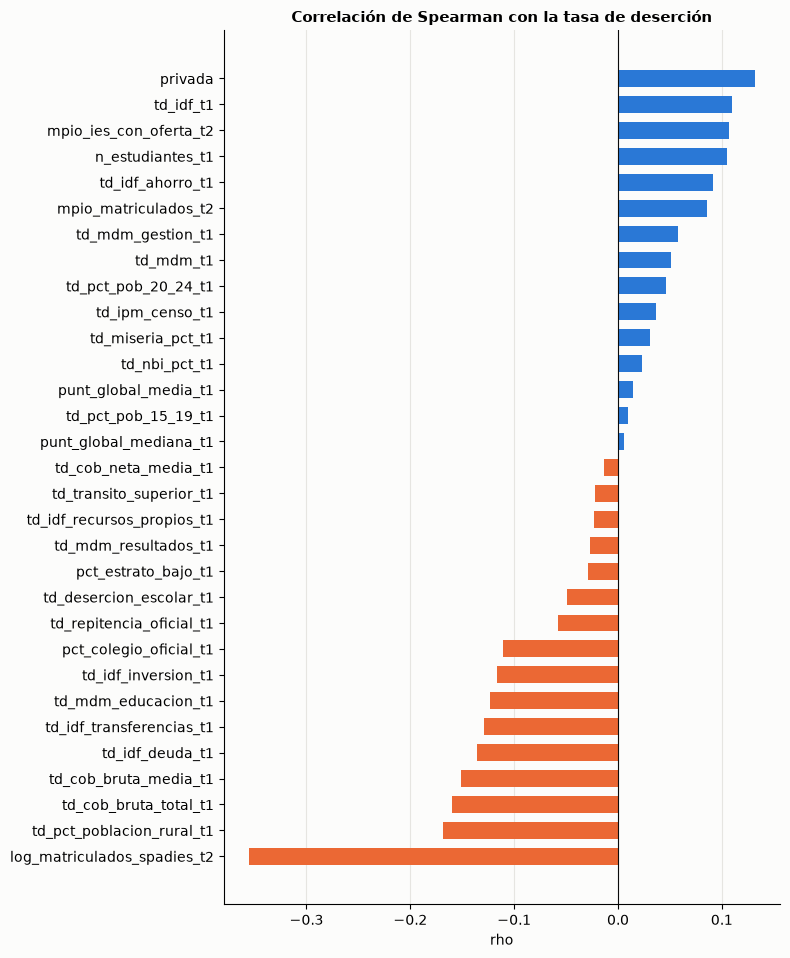

In [21]:
from src.modelado.particion import EXCLUIDAS_POR_DEFECTO, columnas_explicativas

# Las mismas variables que usará el modelado: sin la población absoluta (cambio de base 2005 -> 2018) ni el ratio de diagnóstico
numericas = columnas_explicativas(df)
print("Fuera de las explicativas por defecto:", EXCLUIDAS_POR_DEFECTO)
X = df[numericas].copy()
X["privada"] = (df["naturaleza"] == "Privada").astype(int)

# Spearman: resistente a los valores atípicos de la tasa y a las relaciones no lineales monótonas
corr = X.corrwith(df["tasa_desercion"], method="spearman").dropna().sort_values()
display(corr.round(3).to_frame("rho de Spearman").T)

fig, ax = plt.subplots(figsize=(8, 0.28 * len(corr) + 1))
ax.barh(corr.index, corr.values, color=[AZUL if v >= 0 else NARANJA for v in corr.values], height=0.65)
ax.axvline(0, color="#0b0b0b", lw=0.8)
ax.set(title="Correlación de Spearman con la tasa de deserción", xlabel="rho")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

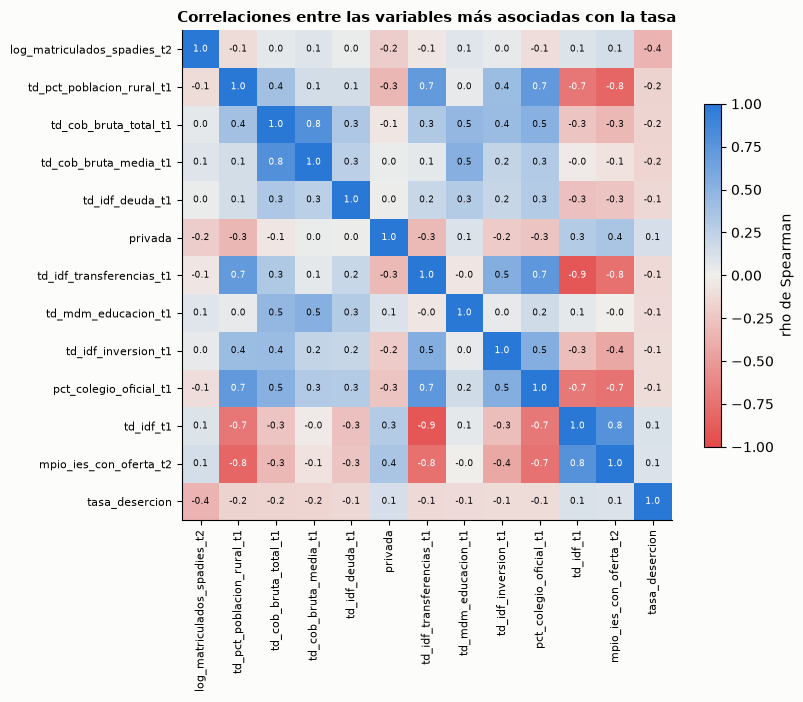

In [22]:
# Las 12 variables más asociadas con la tasa y su correlación entre sí (para detectar redundancia)
top = corr.abs().sort_values(ascending=False).head(12).index.tolist()
mat = X[top + ["privada"] if "privada" not in top else top].assign(tasa_desercion=df["tasa_desercion"]).corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 7))
mapa = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
im = ax.imshow(mat.values, cmap=mapa, vmin=-1, vmax=1)
ax.set_xticks(range(len(mat)), mat.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(mat)), mat.index, fontsize=8)
for i in range(len(mat)):
    for j in range(len(mat)):
        ax.text(j, i, f"{mat.values[i, j]:.1f}", ha="center", va="center", fontsize=6.5,
                color="#0b0b0b" if abs(mat.values[i, j]) < 0.6 else "#ffffff")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="rho de Spearman")
ax.set_title("Correlaciones entre las variables más asociadas con la tasa")
plt.tight_layout()
plt.show()

**Precauciones.** `matriculados_ies_t2` casi coincide con el denominador de la tasa, de modo que su asociación es en parte
mecánica. Varias variables territoriales (TerriData) son muy parecidas entre sí; antes de modelar conviene
reducirlas o regularizarlas. Las IES con sede en una misma ciudad comparten todo su contexto territorial.

## 8. Mapa por departamento

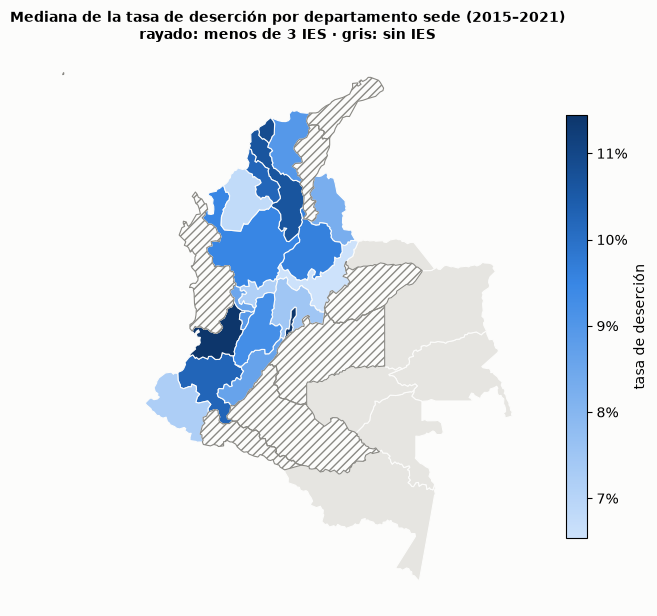

,departamento,mediana,IES
0,La Guajira,0.228,2
1,"Archipielago De San Andres, Providencia Y Sant...",0.214,1
2,Casanare,0.115,1
3,Valle Del Cauca,0.114,30
4,"Bogota, D.C.",0.114,93
5,Atlantico,0.109,16
6,Bolivar,0.107,12
7,Putumayo,0.105,1
8,Cauca,0.102,6
9,Sucre,0.102,3


Rayado: departamentos con 1 o 2 IES (la mediana describe solo a esas instituciones); gris: sin IES en el dataset.


In [23]:
# Polígonos departamentales del DANE (MGN 2018), guardados en data/external; se dibujan con matplotlib sin geopandas
geo = json.loads((ROOT / "data" / "external" / "departamentos_colombia.geojson").read_text(encoding="utf-8"))
valor_todos = df.groupby("cod_depto")["tasa_desercion"].median()
n_ies = df.groupby("cod_depto")["cod_ies"].nunique()
# Con 1 o 2 IES la mediana departamental no es representativa: se pintan aparte y no fijan la escala de color
valor = valor_todos[n_ies.reindex(valor_todos.index) >= 3]

norma = Normalize(vmin=valor.min(), vmax=valor.max())
cmap = LinearSegmentedColormap.from_list("rampa", RAMPA)
parches, colores, pocas = [], [], []
for f in geo["features"]:
    cod = f["properties"]["DPTO_CCDGO"]
    anillo = np.array(f["geometry"]["coordinates"][0])
    parches.append(Polygon(anillo, closed=True))
    if cod in valor.index:
        colores.append(cmap(norma(valor[cod])))
    else:
        colores.append("#fcfcfb" if cod in valor_todos.index else "#e6e5e1")
    pocas.append(cod in valor_todos.index and cod not in valor.index)

fig, ax = plt.subplots(figsize=(6.5, 8))
ax.add_collection(PatchCollection(parches, facecolor=colores, edgecolor="#fcfcfb", linewidth=0.8))
# trama diagonal sobre los departamentos con menos de 3 IES
ax.add_collection(PatchCollection([p for p, m in zip(parches, pocas) if m], facecolor="none", edgecolor=GRIS,
                                  hatch="////", linewidth=0.8))
ax.autoscale_view()
ax.set_aspect("equal")
ax.set_axis_off()
ax.set_title("Mediana de la tasa de deserción por departamento sede (2015–2021)\nrayado: menos de 3 IES · gris: sin IES", fontsize=10)
barra = fig.colorbar(plt.cm.ScalarMappable(norm=norma, cmap=cmap), ax=ax, shrink=0.55, label="tasa de deserción")
barra.ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout()
plt.show()

mapa_tabla = pd.DataFrame({"departamento": valor_todos.index.map(deptos), "mediana": valor_todos.values,
                           "IES": n_ies.reindex(valor_todos.index).values})
display(mapa_tabla.sort_values("mediana", ascending=False).round(3).reset_index(drop=True))
print("Rayado: departamentos con 1 o 2 IES (la mediana describe solo a esas instituciones); gris: sin IES en el dataset.")

## Conclusiones

- **Distribución.** El dataset final tiene 1.928 IES-año de 295 IES. La tasa anual de deserción tiene mediana 9,9 %, media 12,0 % y, entre los percentiles 5 y 95, un rango de 4,3 % a 26,1 %. Sigue siendo muy asimétrica (3,8) y tiene 15 filas por encima de 50 %.
- **Efecto del denominador mínimo.** `min_matriculados_t2 = 100` elimina 97 IES-año (4,5 % de 2.148) y deja a 9 IES sin ninguna fila. Las filas eliminadas tenían mediana 24,8 % y media 27,9 %: eran sobre todo tasas inestables de instituciones chicas. La mediana global casi no cambia (10,0 % → 9,8 %), la media baja de 12,9 % a 12,2 % y el percentil 95 de 31,1 % a 27,7 %. Quita 13 de las 33 filas con tasa > 50 %.
- **Exclusiones por calidad.** Después del mínimo y de 9 IES-año por posible cierre, se excluyen 114 IES-año: 37 por inconsistencia entre SPADIES y SNIES (ratio > 3 o < 1/3, o SNIES sin dato dentro de su cobertura), 85 por régimen especial (lista explícita de escuelas militares y policiales, 13 IES) y 8 en las dos categorías. De las 20 filas con tasa > 50 % que dejaba el mínimo, `inconsistencia_fuentes` elimina 3 (2824, 4826, 9929) y `regimen_especial` 2 (2106, 3114): **salen 5 y quedan 15**. Con esas exclusiones la mediana (9,9 %) y la media (12,0 %) casi no se mueven, pero la desviación baja de 0,093 a 0,087 y el percentil 95 de 27,7 % a 26,1 %. El ratio SPADIES/SNIES del dataset final tiene mediana 0,88 (p25–p75 de 0,79 a 0,97): la matrícula SNIES incluye posgrado y es sistemáticamente mayor.
- **SENA.** El SENA (9110) está en el dataset con 7 IES-año (la bandera `es_sena` está activa y `excluir_sena` apagada). Es atípico por **tamaño, no por tasa**: su matrícula de referencia (SNIES, t-2) es de 426 mil a 468 mil, unas 113 a 128 veces la mediana de las demás IES (3,7 mil) y alrededor de 4 veces la de la mayor otra IES (91 mil a 123 mil). Su tasa, en cambio, es corriente: mediana de 12,4 % (rango 8,2 % a 16,7 %), en los percentiles 29 a 83 de cada año, dentro del p5–p95 de las demás (4,3 % a 26,1 %). **Decisión:** el SENA se mantiene (`excluir_sena: false`) porque su tasa no es atípica, y su tamaño se maneja con `log_matriculados_ies_t2` (log1p), la versión explicativa de la matrícula (la bruta queda en el dataset pero fuera de las explicativas por defecto). El logaritmo baja la asimetría de la matrícula de 13,5 a −0,2 y la distancia del SENA al resto de 40 a 3,5 desviaciones estándar: sigue siendo el valor más alto, pero ya no domina. Como análisis de sensibilidad, `cargar_dataset(cfg, excluir_sena=True)` (o `modelado.excluir_sena: true`) corre el modelado sin sus 7 IES-año; en las filas con matrícula, la tasa mediana (9,7 %) y media (11,7 %) y la correlación con la matrícula (rho −0,35 con y −0,36 sin el SENA) casi no cambian.
- **Composición oficial / privada.** Sin ningún filtro: 321 IES, 95 oficiales (29,6 %) y 226 privadas; tras el mínimo y los posibles cierres: 311 IES, 94 oficiales (30,2 %); en el dataset final: 295 IES, 79 oficiales (26,8 %) y 216 privadas. En IES-año el peso oficial va de 29,7 % a 30,1 % y a 27,3 %. Entre la primera y la última etapa salen 16 IES oficiales y 10 privadas: casi todo el efecto sobre la composición viene del régimen especial (13 escuelas oficiales).
- **Tasas > 50 % que quedan y posible cierre.** Las 15 filas restantes son de 9 IES y ninguna cae en la ventana de posible cierre (los 2 semestres previos al último reporte de una IES que dejó de reportar). El posible cierre no explica estas tasas: son bases chicas o un comportamiento estructural que no se puede determinar con estos datos (la IES 9903 tiene tasas de 63 % a 99 % en cinco años). La lista completa, con las banderas, está en `reports/tasas_altas.csv`.
- **Evolución.** La mediana baja de 10,6 % en 2015 a 9,1 % en 2021 y la media de 13,3 % a 11,3 %, con un máximo en 2017 (11,1 % de mediana). No se ve un salto en 2020; con siete años y un denominador rezagado no conviene leerlo como efecto de la pandemia.
- **Oficial y privada.** Las privadas (216 IES) tienen mediana 10,2 % y media 12,6 %; las oficiales (79 IES), 8,7 % y 10,6 %. La diferencia se mantiene en el tiempo (gráfico de líneas), pero las filas de una misma IES no son independientes, así que el valor p de Mann-Whitney solo es orientativo. Al sacar las escuelas militares y policiales el dataset pierde 15 IES oficiales.
- **Departamentos.** Entre los 19 departamentos con 3 o más IES, Bogotá (11,4 %), Valle del Cauca (11,4 %), Atlántico (10,9 %) y Bolívar (10,7 %) tienen las medianas más altas; Boyacá (6,5 %), Córdoba (6,8 %) y Caldas (7,2 %), las más bajas. Esas diferencias mezclan efecto territorial con composición (peso de privadas, tamaño de las IES). Los 8 departamentos con 1 o 2 IES describen solo a esas instituciones (el mapa los marca aparte).
- **Nulos por bloques de años.** Los nulos de las explicativas no son aleatorios: vienen en bloques de años y el dataset trae un indicador 0/1 por bloque. MDM y SNIES faltan en **2015 y 2016** (MDM empieza en 2016 y SNIES por programa en 2015, con rezagos t-1 y t-2) y Saber 11 falta en **2019 y 2021** (se excluyen los años 2018, 2020 y 2021 con cobertura incompleta del calendario A, y los rezagos los desplazan). Por eso `falta_mdm`, `falta_snies` y `falta_saber11` valen 1 en el 100 % de esos años y 0 en el resto. **Efecto en la partición temporal** (entrenamiento 2015–2019, prueba 2020–2021): en el entrenamiento falta Saber 11 en 19,8 % de las filas y MDM y SNIES en 40,4 %; en la prueba falta Saber 11 en 49,8 % (todo 2021), MDM en 0,4 % y SNIES en 0 %. Es decir, la mitad de la prueba se predice con Saber 11 imputado y el modelo ve MDM/SNIES incompletos solo en el entrenamiento. Con la ventana 2017–2021 el entrenamiento (2017–2019, 825 filas) tiene MDM y SNIES completos y Saber 11 ausente en 33,2 %. TerriData tiene hasta 29,1 % de nulos (todos en el MDM) y se descartaron 5 variables por más de 50 % (cobertura en educación superior y todo el bloque de mercado laboral). **Limitación:** el modelado no podrá usar variables de mercado laboral municipal.
- **Tamaño de la IES.** La variable de tamaño por defecto es `log_matriculados_spadies_t2` (log1p del denominador de la tasa, información de t-2): está completa en 2015–2021, mientras que `log_matriculados_ies_t2` (SNIES, alternativa) falta en 29 % por el bloque 2015–2016. Se parecen casi del todo (rho 0,99) y su correlación con la tasa es la misma (−0,36 y −0,35). No es fuga, pero sí una relación mecánica: el denominador es el de la propia tasa.
- **Correlaciones.** Ninguna variable explica mucho por sí sola (|rho| ≤ 0,36). La más fuerte es negativa: `log_matriculados_spadies_t2` (-0,36); IES más grandes, menor tasa, en parte por construcción, porque es el denominador (el logaritmo es monótono: la correlación de Spearman es la misma que la de la matrícula bruta). Le siguen el porcentaje de población rural (-0,17) y la cobertura bruta (-0,16 total, -0,15 media), y, con signo positivo, ser privada (+0,13), el indicador de desempeño fiscal (+0,11), el número de IES del municipio (+0,11) y los estudiantes de Saber 11 (+0,11). El análisis ya excluye la población absoluta (`td_poblacion_total_t1`, por el cambio de base 2005 → 2018) y el ratio de diagnóstico, igual que las explicativas por defecto del modelado. Las variables territoriales son colineales entre sí (matrícula municipal, estudiantes de Saber 11 e IES del municipio), de modo que habrá que reducirlas o regularizarlas.
- **Para el modelo.** La partición queda preparada en `src/modelado/particion.py` (GroupKFold por IES y partición temporal 2015–2019 / 2020–2021, con la opción `ventana_modelado` para la sensibilidad 2017–2021, y un preprocesador con one-hot para `sector` y `caracter`) y el objetivo puede transformarse con logit (`config.yaml: modelado.transformacion_objetivo`, `src/modelado/objetivo.py`), útil por la asimetría de la tasa. Pendientes: tratamiento de las 15 tasas atípicas que quedan, colinealidad territorial, el solapamiento entre `matriculados_ies_t2` y el denominador de la tasa y las retroproyecciones del DANE base 2018 para volver a usar la población absoluta.